In [1]:
# (generated with Gemini)

import matplotlib.pyplot as plt
import numpy as np
from sklearn.datasets import fetch_openml
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from scipy.ndimage import shift, rotate, zoom

# 1. Load Data & Subsample

In [6]:
X_raw, y_raw = fetch_openml("mnist_784", version=1, return_X_y=True, as_frame=False)
X_raw = X_raw / 255.0  # Normalize to [0, 1]
y_raw = y_raw.astype(int)

X_train, X_val, y_train, y_val = train_test_split(
    X_raw, y_raw, train_size=10000, test_size=1000, random_state=42, stratify=y_raw
)

k_values = [1, 3, 5, 7, 9]


# 2. Baseline KNN Evaluation


In [7]:
print("--- Baseline KNN ---")
baseline_accs = []
knn_models = {}

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k, metric="euclidean", n_jobs=-1)
    knn.fit(X_train, y_train)
    preds = knn.predict(X_val)
    acc = accuracy_score(y_val, preds)
    baseline_accs.append(acc)
    knn_models[k] = (knn, preds)
    print(f"k={k} Validation Accuracy: {acc:.4f}")



--- Baseline KNN ---
k=1 Validation Accuracy: 0.9580
k=3 Validation Accuracy: 0.9580
k=5 Validation Accuracy: 0.9510
k=7 Validation Accuracy: 0.9500
k=9 Validation Accuracy: 0.9480


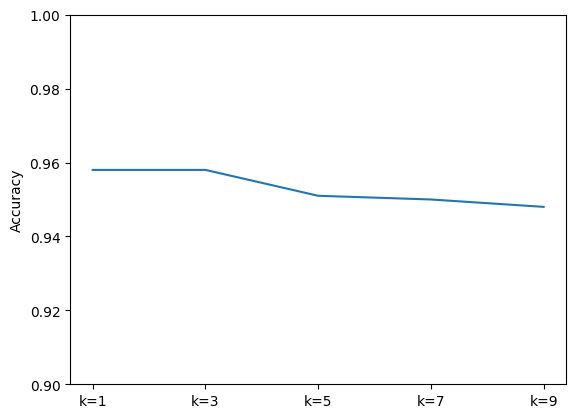

In [8]:
plt.plot(baseline_accs)
plt.ylabel("Accuracy")
plt.ylim([0.9, 1.])
plt.xticks(np.arange(len(k_values)), [f"k={k}" for k in k_values])
plt.show()

# 3. Visualize Baseline Misclassifications (k=3)

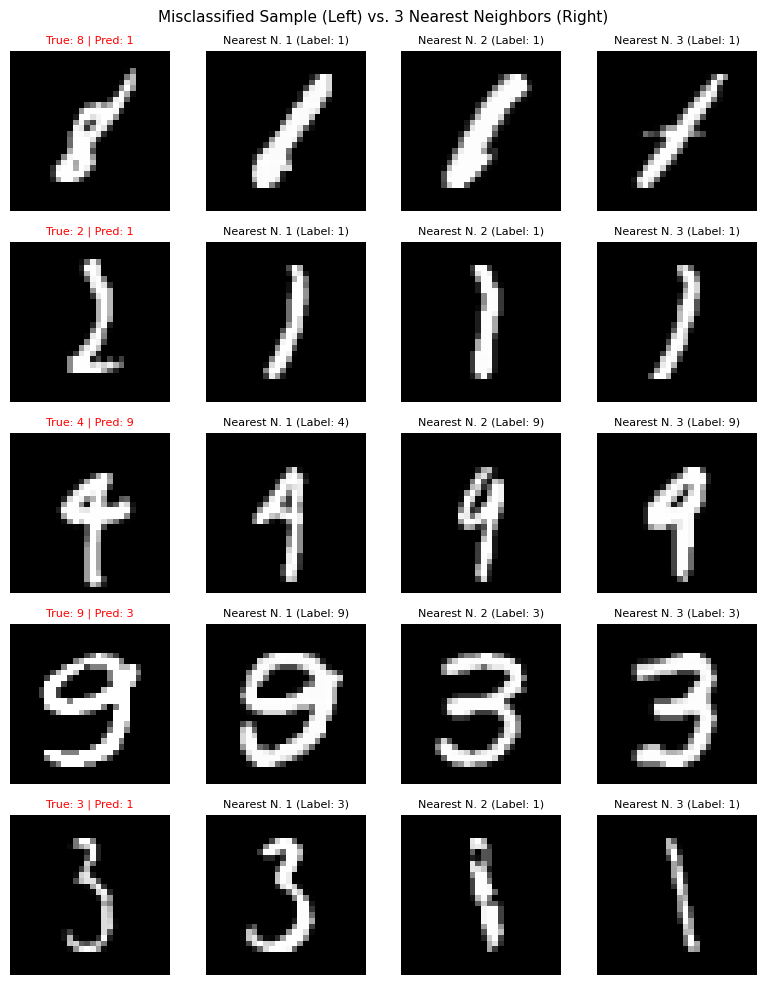

In [9]:
best_k = 3
knn_best, preds_best = knn_models[best_k]
misclassified_idx = np.where(preds_best != y_val)[0][:5]  # Take 5 misclassified examples

# Get indices of nearest neighbors in the training set
distances, indices = knn_best.kneighbors(X_val[misclassified_idx], n_neighbors=3)

fig, axes = plt.subplots(len(misclassified_idx), 4, figsize=(8, 2 * len(misclassified_idx)))
fig.suptitle("Misclassified Sample (Left) vs. 3 Nearest Neighbors (Right)", fontsize=11)

for row, idx in enumerate(misclassified_idx):
    # Plot target test image
    axes[row, 0].imshow(X_val[idx].reshape(28, 28), cmap="gray")
    axes[row, 0].set_title(f"True: {y_val[idx]} | Pred: {preds_best[idx]}", color="red", fontsize=8)
    axes[row, 0].axis("off")
    
    # Plot its 3 nearest neighbors
    for col, neighbor_idx in enumerate(indices[row]):
        axes[row, col + 1].imshow(X_train[neighbor_idx].reshape(28, 28), cmap="gray")
        axes[row, col + 1].set_title(f"Nearest N. {col+1} (Label: {y_train[neighbor_idx]})", fontsize=8)
        axes[row, col + 1].axis("off")

plt.tight_layout()
plt.show()